# Lesson 09 - Distance and speed

Class is a **classification** problem (pick one of 12). Distance and speed are **regression** problems:
predict a number. The same network does it; only the output head and the loss change.

```
python src/train.py --task distance --init-from runs/class_f1_efficientnet_b0_vessel/best.pt
python src/evaluate.py runs/distance_f1_efficientnet_b0_vessel
python src/train.py --task speed --init-from runs/class_f1_efficientnet_b0_vessel/best.pt
python src/evaluate.py runs/speed_f1_efficientnet_b0_vessel
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as Fn
import data as D
from paths import DATA_DIR, RUNS_DIR

mel, table = D.open_features(DATA_DIR)
RUNS = {"distance": RUNS_DIR / "distance_f1_efficientnet_b0_vessel", "speed": RUNS_DIR / "speed_f1_efficientnet_b0_vessel"}

## 1. The loss: Huber

- **Squared error** punishes big mistakes very hard, so a few clips with bad GPS positions would dominate.
- **Absolute error** treats all mistakes alike, but its gradient never shrinks near the answer, which makes
  training jumpy.
- **Huber** is squared for small errors and absolute for large ones: the best of both. We use it with δ = 0.2,
  on targets scaled to km (distance) and knots/10 (speed). So errors beyond 200 m or 2 knots count linearly.

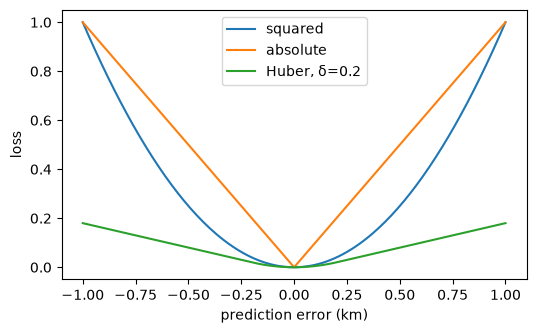

In [2]:
e = torch.linspace(-1, 1, 201)
plt.figure(figsize=(6, 3.5))
plt.plot(e, e ** 2, label="squared"); plt.plot(e, e.abs(), label="absolute")
plt.plot(e, Fn.huber_loss(e, torch.zeros_like(e), reduction="none", delta=0.2), label="Huber, δ=0.2")
plt.xlabel("prediction error (km)"); plt.ylabel("loss"); plt.legend(); plt.show()

## 2. Why start from the class model?

Lesson 02 showed that loudness relates to distance only weakly across all ships (a big ship far away can be
as loud as a small boat nearby), but strongly *within* a ship type. A network that already recognises ship types
has the features needed to judge "loud *for a tanker*". `--init-from` copies those weights in, and only the
distance head starts from scratch. The same holds for speed: propeller and engine sounds change with speed
differently for each type of ship.

Background clips are left out of both tasks (there is no ship, so no distance or speed).

## 3. Results

The bar to beat is the error of always guessing the training median: about 400 m for distance and 3.6 knots
for speed (fold 1).

In [3]:
for task, run in RUNS.items():
    path = run / "eval" / "metrics.json"
    if not path.exists():
        print(f"no {task} evaluation yet:\n  python src/train.py --task {task} --init-from runs/class_f1_efficientnet_b0_vessel/best.pt"
              f"\n  python src/evaluate.py {run.relative_to(ROOT).as_posix()}")
        continue
    r = json.loads(path.read_text())["regression"][task]
    print(f"{task}: MAE {r['mae']:.1f} {r['unit']} (median error {r['median_ae']:.1f}) vs always-median guess "
          f"{r['baseline_mae']:.1f} {r['unit']} | right band {r['band_accuracy']:.1%} | {r['n']} test clips")

distance: MAE 275.4 m (median error 216.0) vs always-median guess 403.0 m | right band 61.5% | 4106 test clips
speed: MAE 2.9 knots (median error 1.7) vs always-median guess 3.6 knots | right band 62.0% | 4115 test clips


## 4. Where are the errors?

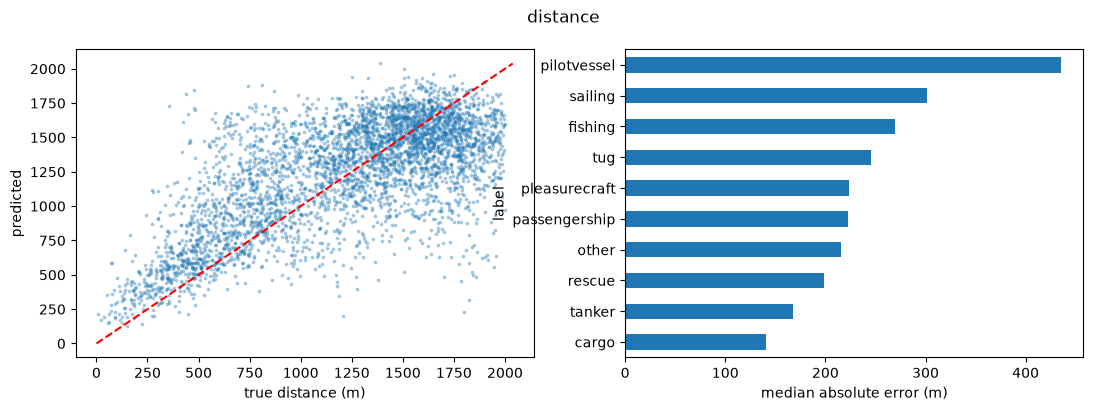

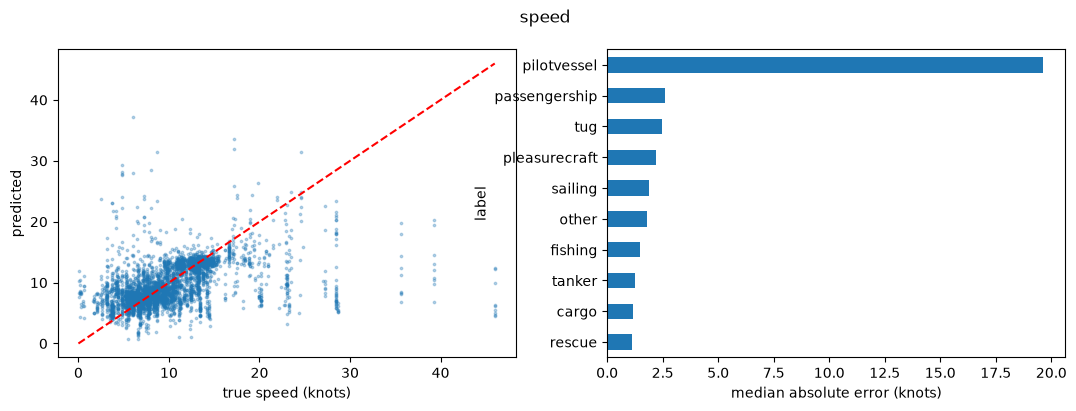

In [4]:
for task, run in RUNS.items():
    p_path = run / "eval" / "predictions.parquet"
    if not p_path.exists():
        continue
    p = pd.read_parquet(p_path).merge(table[["mean_distance", "mean_sog"]], left_on="row", right_index=True)
    true, pred, unit = (p.mean_distance, p.pred_distance_m, "m") if task == "distance" else (p.mean_sog, p.pred_speed_kn, "knots")
    p["abs_error"] = (pred - true).abs()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].scatter(true, pred, s=3, alpha=0.3); lim = [0, max(true.max(), pred.max())]
    ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel(f"true {task} ({unit})"); ax[0].set_ylabel("predicted")
    p.groupby("label").abs_error.median().sort_values().plot.barh(ax=ax[1])
    ax[1].set_xlabel(f"median absolute error ({unit})"); fig.suptitle(task); plt.show()

Typical patterns:
- predictions pulled towards the middle (far ships predicted closer, near ships farther): the model hedges
  when unsure,
- small boats (pleasure craft, sailing) have larger distance errors: they are quiet, so loudness says less,
- the evaluation also reports accuracy in **bands** (near < 700 m, mid, far > 1,400 m), which is often the
  more honest way to present this to a sonar operator.

## Try it

1. Train distance **without** `--init-from` (add `--name distance_scratch`). How much did starting from the
   class model help?
2. Try `--task multi`: one network learns class, distance and speed together. Compare with the separate models.